In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Data Validation
- Week: Integer, 15000 entries, no null values, no cleaning need
- sales_method: more than 3 unique due to misspelings, I cleaned it by replacing the wrong entries with the correct entries and converted the column to category
- customer_id: Unique Identifier, no duplicates, no cleaning needed.
- revenue: 13926 entries out of 15000. Replaced null values in revenue with the mean by 'nb_sold' and 'sales_method' to maintain the observed trend
- years_as_customer: numeric values without missing values, same as the description. No cleaning is needed.
- nb_site_visits: numeric values without missing values, same as the description. No cleaning is needed.
- state: Character, without any missing values, correct locations and not more than the 50 states of U.S where the company is based.  No  cleaning needed
- nb_sold: numeric values without missing values, same as the description. No cleaning is needed.
- estimated sale time: A new column I created to identify the estimated amount of time spent to sell the product by each method, using 30 minutes for the Call method and 10 minutes for the Email+Call as described in the Email sent from the sales department, and 2 minutes for the Email method as it was described to take very little week for the team
- revenue per estimated sales minutes: A metric column based on th estimated sale time to calculate how much time is spent to get revenue

After the data validation, the dataset contains 15000 rows and 10 columns without missing values.

##  Data Valadition

The original dataset has 15000 rows and 8 columns.

- The week column contains integer values from 1-6 corresponding to each week and 0 null values. No changes to this column were necessary.
- The sales_method column contains 5 different unique values (Email, Call, Email + Call, em + call, email) and 0 null values. The column should only contain 3 unique values corresponding to each type of sales method. Upon inspection of the values in this column simple mistakes such as different capitalization and use of abbrevations created two extra sets of values. Changes were made and after cleaning the column only contains the following 3 different value types corresponding to each alternate sales method: Email, Call, Email + Call
- The customer_id column contains unique identifiers for each customer and had no missing values. No changes to this column were required.
- The revenue column had 1074 missing values. I decided that the best approach to handle these missing values would be to replace them by the mean revenue corresponding to each type of sales_method.
- The years_as_customer column has 0 missing values, however we had 2 rows with invalid values. Since our company was founded in 1984, the maximum amount of years we could have any given customer is 39. Two rows had values with 47 and 63, which we know is not possible. I assume this was just a mistake in data entry, and I will replace these two values with 39.
- The nb_site_visits column has 0 missing values and all data is valid. No changes needed to be made to this column
- The state The column has 0 missing values and 50 unique values corresponding to each state. No changes need to be made to this column

Finally after all the data validation and cleaning I checked for any duplicate rows and found none. After cleaning and validating the data our dataset contains 15000 rows and 8 columns with 0 missing values.

In [3]:
data  = pd.read_csv("D:\Documents\Projects\product_sales.csv")
data.head(15)

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\user\AppData\Local\Temp\ipykernel_8164\317384199.py:1: SyntaxWarning: invalid escape sequence '\D'
  data  = pd.read_csv("D:\Documents\Projects\product_sales.csv")


,week,sales_method,customer_id,nb_sold,revenue,years_as_customer,nb_site_visits,state
0,2,Email,2e72d641-95ac-497b-bbf8-4861764a7097,10,NaN,0,24,Arizona
1,6,Email + Call,3998a98d-70f5-44f7-942e-789bb8ad2fe7,15,225.47,1,28,Kansas
2,5,Call,d1de9884-8059-4065-b10f-86eef57e4a44,11,52.55,6,26,Wisconsin
3,4,Email,78aa75a4-ffeb-4817-b1d0-2f030783c5d7,11,NaN,3,25,Indiana
4,3,Email,10e6d446-10a5-42e5-8210-1b5438f70922,9,90.49,0,28,Illinois
5,6,Call,6489e678-40f2-4fed-a48e-d0dff9c09205,13,65.01,10,24,Mississippi
6,4,Email,eb6bd5f1-f115-4e4b-80a6-5e67fcfbfb94,11,113.38,9,28,Georgia
7,1,Email,047df079-071b-4380-9012-2bfe9bce45d5,10,99.94,1,22,Oklahoma
8,5,Email,771586bd-7b64-40be-87df-afe884d2af9e,11,108.34,10,31,Massachusetts
9,5,Call,56491dae-bbe7-49f0-a651-b823a01103d8,11,53.82,7,23,Missouri


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   week               15000 non-null  int64  
 1   sales_method       15000 non-null  object 
 2   customer_id        15000 non-null  object 
 3   nb_sold            15000 non-null  int64  
 4   revenue            13926 non-null  float64
 5   years_as_customer  15000 non-null  int64  
 6   nb_site_visits     15000 non-null  int64  
 7   state              15000 non-null  object 
dtypes: float64(1), int64(4), object(3)
memory usage: 937.6+ KB


In [5]:
#validating the state columns to make sure that there are no more than 50 states
data['state'].nunique() > 50


False

In [6]:
#check visually for any out of place entry
data['state'].unique()

array(['Arizona', 'Kansas', 'Wisconsin', 'Indiana', 'Illinois',
       'Mississippi', 'Georgia', 'Oklahoma', 'Massachusetts', 'Missouri',
       'Texas', 'New York', 'Maryland', 'California', 'Tennessee',
       'Pennsylvania', 'North Dakota', 'Florida', 'Michigan',
       'North Carolina', 'Hawaii', 'Colorado', 'Louisiana', 'Virginia',
       'New Mexico', 'Arkansas', 'Alaska', 'Oregon', 'New Hampshire',
       'Ohio', 'New Jersey', 'Connecticut', 'Iowa', 'Montana',
       'Washington', 'Kentucky', 'Alabama', 'Nebraska', 'South Carolina',
       'Minnesota', 'South Dakota', 'Delaware', 'Maine', 'Utah',
       'West Virginia', 'Vermont', 'Rhode Island', 'Nevada', 'Idaho',
       'Wyoming'], dtype=object)

In [7]:


# Example: replace 'em + call' with 'Email + Call' in the sales_method column
data['sales_method'] = data['sales_method'].replace(['em + call', 'email'],['Email + Call','Email'])

data['sales_method'] = data['sales_method'].astype('category')

print(data['sales_method'].dtype)


category


In [8]:
#fiirst step of checking for duplicates
data['customer_id'].nunique()

15000

In [9]:
#checking the nb_sold column
data['nb_sold'].value_counts()

nb_sold
10    3677
9     3535
11    2439
8     1941
12    1088
13     939
7      698
15     555
14      97
16      31
Name: count, dtype: int64

In [10]:
#validating nb_site_visits column
data['nb_site_visits'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 15000 entries, 0 to 14999
Series name: nb_site_visits
Non-Null Count  Dtype
--------------  -----
15000 non-null  int64
dtypes: int64(1)
memory usage: 117.3 KB


In [11]:
#validating nb_site_visits column
data['years_as_customer'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 15000 entries, 0 to 14999
Series name: years_as_customer
Non-Null Count  Dtype
--------------  -----
15000 non-null  int64
dtypes: int64(1)
memory usage: 117.3 KB


In [12]:
#calculating percentage of null values to check if it is less than the 5% rule of thumb, it is not.
num = data['revenue'].isnull().sum()
denom = data['revenue'].count()

na_percentage = num/denom * 100

na_percentage

7.7121930202498925

In [13]:
#investigating revenue by sales method to check if it is within reason to replace null values with these numbers
grouped_data = data.groupby(['nb_sold', 'sales_method'])['revenue'].mean()
#replaced null values in revenue with the mean by 'nb_sold' and 'sales_method'
data['revenue'] = data.apply(
    lambda row: grouped_data.get((row['nb_sold'], row['sales_method'])) if pd.isnull(row['revenue']) else row['revenue'],
    axis=1
)
data['revenue'].isna().sum()

C:\Users\user\AppData\Local\Temp\ipykernel_8164\2508422068.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(['nb_sold', 'sales_method'])['revenue'].mean()


0

In [14]:
data.head()

,week,sales_method,customer_id,nb_sold,revenue,years_as_customer,nb_site_visits,state
0,2,Email,2e72d641-95ac-497b-bbf8-4861764a7097,10,99.755544,0,24,Arizona
1,6,Email + Call,3998a98d-70f5-44f7-942e-789bb8ad2fe7,15,225.470000,1,28,Kansas
2,5,Call,d1de9884-8059-4065-b10f-86eef57e4a44,11,52.550000,6,26,Wisconsin
3,4,Email,78aa75a4-ffeb-4817-b1d0-2f030783c5d7,11,108.719054,3,25,Indiana
4,3,Email,10e6d446-10a5-42e5-8210-1b5438f70922,9,90.490000,0,28,Illinois


In [15]:
#check for null values in other columns
data.isnull().sum()

week                 0
sales_method         0
customer_id          0
nb_sold              0
revenue              0
years_as_customer    0
nb_site_visits       0
state                0
dtype: int64

In [16]:
data['week'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 15000 entries, 0 to 14999
Series name: week
Non-Null Count  Dtype
--------------  -----
15000 non-null  int64
dtypes: int64(1)
memory usage: 117.3 KB


In [17]:
data['sales_method'].unique()

['Email', 'Email + Call', 'Call']
Categories (3, object): ['Call', 'Email', 'Email + Call']

In [18]:
#creating the estimated sale time column from the sales method column in other to create a metric later
data['estimated sale time'] = data['sales_method'].map({
    'Email': 2,
    'Call': 30,
    'Email + Call': 10
})


In [19]:
data['estimated sale time']=data['estimated sale time'].astype(int)

In [20]:
data['revenue per estimated sales minutes'] =  data['revenue']/data['estimated sale time']
data['revenue per estimated sales minutes'].head()

0    49.877772
1    22.547000
2     1.751667
3    54.359527
4    45.245000
Name: revenue per estimated sales minutes, dtype: float64

### How many customers were there for each approach?
- In the six weeks after the product launch, the sales team were able to get 4962 (33.08%) customers through calls, 7466 (49.77%) through Email, and 2572 (17.15%) through the Emails and calls combination.
- This shows that the Email method is the most effective method in bringing in customers, followed by the Call method.

In [21]:
customers_by_method = data.groupby('sales_method')['customer_id'].count()
pct_of_customers_by_method = (customers_by_method/15000)*100
pct_customers = pd.DataFrame({'Percentage of customers':pct_of_customers_by_method})
pct_customers

C:\Users\user\AppData\Local\Temp\ipykernel_8164\158419504.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  customers_by_method = data.groupby('sales_method')['customer_id'].count()


,Percentage of customers
sales_method,
Call,33.080000
Email,49.773333
Email + Call,17.146667


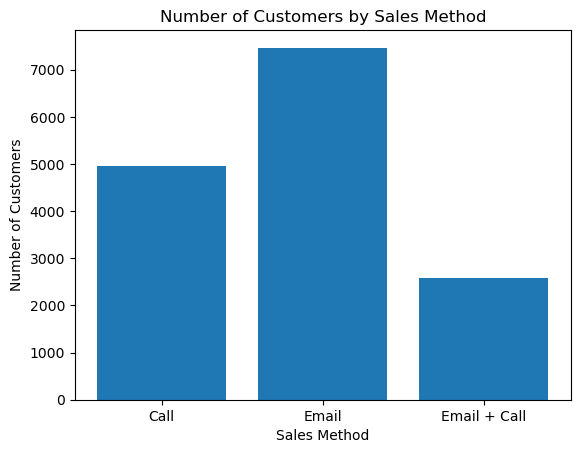

In [22]:
plt.bar(customers_by_method.index, customers_by_method.values)
plt.xlabel('Sales Method')
plt.ylabel('Number of Customers')
plt.title('Number of Customers by Sales Method')
plt.show()

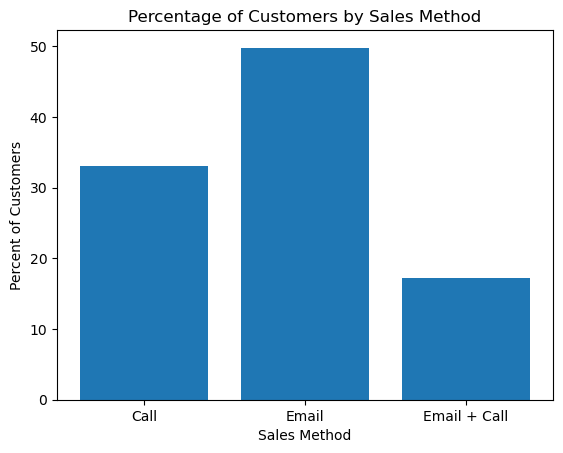

In [23]:
plt.bar(pct_customers.index, pct_customers['Percentage of customers'])
plt.xlabel('Sales Method')
plt.ylabel('Percent of Customers')
plt.title('Percentage of Customers by Sales Method')
plt.show()

In [24]:
print(data[data['sales_method'] == 'Call']['revenue'].max(), data[data['sales_method'] == 'Call']['revenue'].min())

71.36 32.54


In [25]:
(data['revenue'].std() / data['revenue'].mean())*100

50.54763301295229

In [26]:
spread = data.groupby('sales_method')['revenue'].agg(['mean', 'std', 'median'])
spread['C of V in %'] =  (spread['std']/spread['mean'])*100
spread

C:\Users\user\AppData\Local\Temp\ipykernel_8164\3977875585.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  spread = data.groupby('sales_method')['revenue'].agg(['mean', 'std', 'median'])


,mean,std,median,C of V in %
sales_method,,,,
Call,47.641601,8.613548,49.265,18.079888
Email,97.185047,11.188283,95.790,11.512350
Email + Call,184.225666,29.106248,184.500,15.799236


### What does the spread of the revenue look like overall? And for each method?
The spread of revenue, as can be seen by the histogram is not normally distributed. Revenue, with a mean of 95.7USD and a standard deviation of 48USD shows that revenue values are volatile. Given a coefficient of variabilty(C of V)  i.e standard deviation/mean of approximately 50%,  it shows that the typical sale is around 96, but revenues often swing up or down by about 50% of that. It is a high-variability sales process.

When revenue is broken down by sales method, we can see that the Email+Call method has the highest standard deviation value of 29.11, but considering it also has the highest mean(184USD) of the other methods and a C of V 16%, this indicates that this method of sales leads to fairly consistent and stable revenues as well as Very high revenues relative to other methods.
The other methods, Call and Email, have standard deviations of 8.61 and 11.19 respectively and coefficients of variation of 18% and 11% respectively. This shows that all 3 methods are fairly consistent in the level of revenue that they genrate, but the Email is the most reliable and the Call method is more volatile  in relation to  it's mean.


From the multiple boxplots, we can see that the range of revenue brought in by the Calls method is between 71 and 32 in USD,  which is far lower than the ranges of the other methods. The Email method has quite a bit of outliers, meaning it occasionally brings in unusually high amounts of  revenue, whilst the Email+Call method is clearly the highest revenue channel with a higher range than the other methods and no outliers. 
This plot butress the points above, that the Call method is the least profitable method (with a median value of 49USD) with consistently low revenues, the Email method alone brings in moderate levels of revenue (with a median value of 95USD) and at a reasonably consistent level, and that the Email+Call method brings in the most revenue and at reasonable level of risk.


This analysis shows that the Call method may not be the most effective method of sales in terms of revenue.


In [27]:
print(data.loc[data['sales_method']== 'Email + Call', 'revenue'].max(), data.loc[data['sales_method']== 'Email + Call', 'revenue'].min())

238.32 122.11


In [28]:
#spread[['mean', 'median', 'std', 'C of V']].plot(kind='bar')
#plt.xlabel('Sales Method')
#plt.ylabel('Value')
#plt.title('Mean, Std, and Coefficient of Variation by Sales Method')
#plt.show()

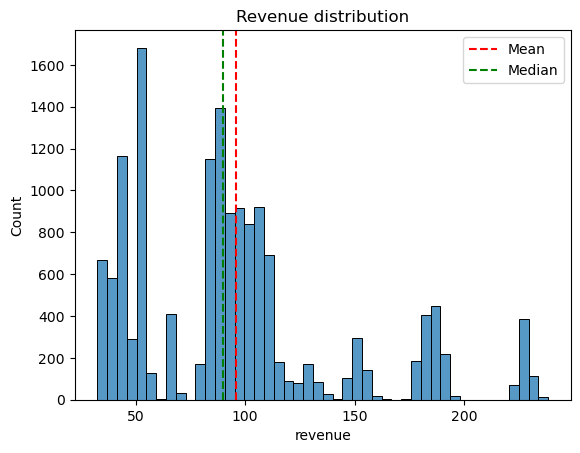

In [29]:
sns.histplot(data=data, x='revenue')
plt.axvline(data['revenue'].mean(), linestyle= 'dashed', color='red', label='Mean')
plt.axvline(data['revenue'].median(), linestyle='dashed', color='green', label='Median')
plt.title('Revenue distribution')
plt.legend()
plt.show()

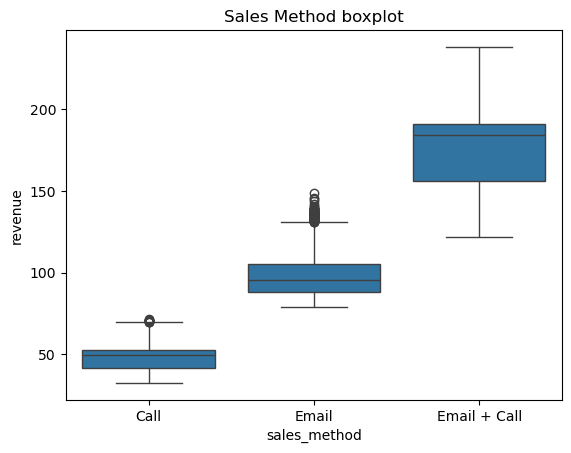

In [30]:
sns.boxplot(data=data, x='sales_method', y='revenue',
            order=data['sales_method'].cat.categories)
plt.title('Sales Method boxplot')
plt.show()

### Difference in revenue over time for each of the methods

The Line graph below shows that revenues in general were highest on the first week of revenue then dipped during the second and third week, rose during the fourth week and the 5th week and then a very steep  dive during  the sixth week.

Breaking down revenues by the method of sales, using a clustered bar chart seems to explain the behaviour of the revenue trend. In the first 4 weeks of the product release, the revenue was driven by the Email sales method. Sending an Email when the product line was launched seemed to be very effective in the first few weeks and then following up with another email three weeks later seemed to bump the revenues from the Email method just as it was declining.

A further look at the chart shows that the Email+Call method's contribution to revenue was consistently rising, which led to the upward trend in week 4 and week 5. All three method's revenue value dropped in week 6 and that is why there was such a dip in that week, but still the Email+Call remained relatively high, showing that it is the best method during the latter phases of post-launch.

The Call method  on the other hand was consistently the lowest contributor of revenue. It's contribution was rising consistently until the final week and eventually contributed more than the Email method on the sixth week, but without further data, I cannot conclude if the Call method would be better than the Email method in the Long-Run.




C:\Users\user\AppData\Local\Temp\ipykernel_8164\3159780006.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rev_by_week_n_method = data.groupby(['week', 'sales_method'])['revenue'].sum()


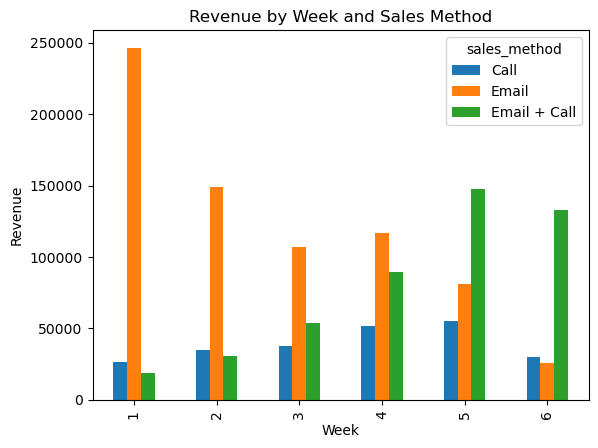

In [31]:
rev_by_week_n_method = data.groupby(['week', 'sales_method'])['revenue'].sum()

rev_by_week_n_method.unstack('sales_method').plot(kind='bar')
plt.xlabel('Week')
plt.ylabel('Revenue')
plt.title('Revenue by Week and Sales Method')
plt.show()

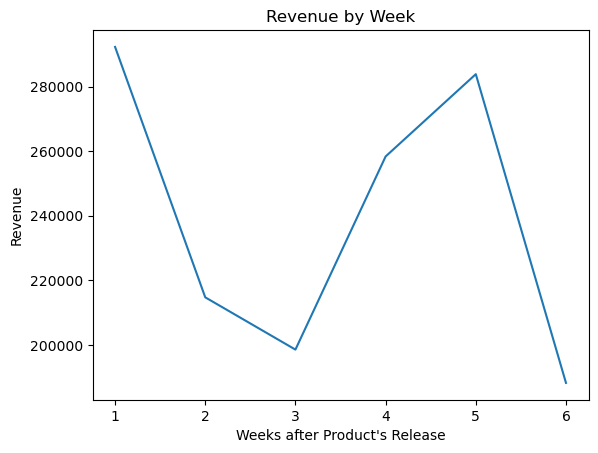

In [32]:
rev_by_week = data.groupby('week')['revenue'].sum()
plt.plot(rev_by_week.index, rev_by_week.values)
plt.xlabel("Weeks after Product's Release")
plt.ylabel('Revenue')
plt.title('Revenue by Week')
plt.show()

## Business Metrics
Since our goal is to make sure we are using the best techniques to sell the new product effectively, in terms of time and revenue, the best metric to use the **Revenue per Estimtated Sales Time**, which calculates the revenues divided by the time used to sell the product with regards to the method of sales.
Analyzing with this metric and getting the percentages of each method's contribution in terms of revenue and time, we will see that the Call method took 78.5% of the total time used in generating revenue whilst only bringing in 16.5% of said revenue which is very very inefficient, Email took 8% of the sales time and generated 50% of the Revenue, and the Email+Call method took 14% of the time and generated 33% of the revenue 

Eliminating the  Call method should help in achieving your goal of selling efficiently


C:\Users\user\AppData\Local\Temp\ipykernel_8164\2891496844.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  time_pct = (data.groupby('sales_method')['estimated sale time'].sum() / total_time_of_sales)*100
C:\Users\user\AppData\Local\Temp\ipykernel_8164\2891496844.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rev_pct = (data.groupby('sales_method')['revenue'].sum()/total_revs)*100


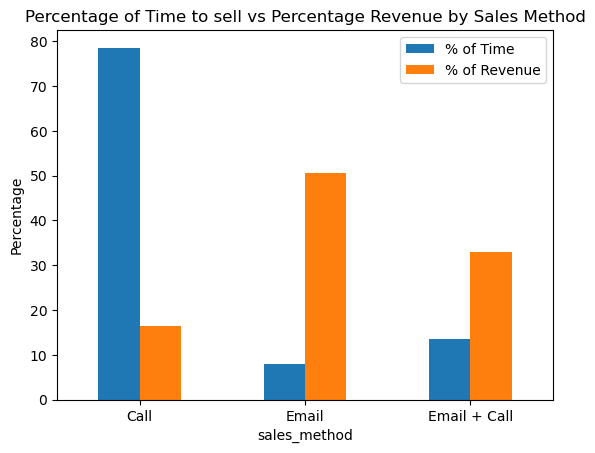

In [33]:
import numpy as np
total_time_of_sales = data['estimated sale time'].sum()
time_pct = (data.groupby('sales_method')['estimated sale time'].sum() / total_time_of_sales)*100

total_revs= data['revenue'].sum()
rev_pct = (data.groupby('sales_method')['revenue'].sum()/total_revs)*100

# Combine into a DataFrame for plotting
metrics_df = pd.DataFrame({
    '% of Time': time_pct,
    '% of Revenue': rev_pct
})

metrics_df.plot(kind='bar', rot=0)
plt.ylabel('Percentage')
plt.title('Percentage of Time to sell vs Percentage Revenue by Sales Method')
plt.legend()
plt.show()

## Recommendations
### Recommendations based on the data
-  Based on the data, it would be wise to focus on Email marketing at the beginning, and then move towards the Email+Call method later on, according to this data that would be around the 5th week.
-  Drop the Call method entirely. The **'Revenue per Minute'** bar graph shows that the Call method is inefficient in terms of time and effort to  get its revenues relative to other methods. The opportuninty cost of using the Call method is too high, I recommend to scrap the method completely and use the man hours saved to use the Email method in the first few weeks of the next productt launch and then to switch to the Email+Call method later down the line.  
- Drop the Email method entirely as a sales method after 6th week, only using the Email+Call method from now on. 
- Collect more data. Knowing the cost attributed to each method would help in assessing their efficiency, also the price and products are key contexts in knowing what is really driving revenue and improving efficiency.
- Try other sales methods like advertising and/or digital marketing, and using key metrics like cost-revenue to further make your selling process more efficient.
- Implement the first and second recommendations as soon as possible to save both time and gain more revenue.
- Correlation analysis shows a significant positive relationship between the number of customers who visited the company site and revenue, that avenue should be looked into more.
- The Call method is useful in getting customers, but this fact is irrelevant as it does not translate to significant revenue and the use of Email is more efficient in getting customers and revenues, and more resources should be diverted there.




C:\Users\user\AppData\Local\Temp\ipykernel_8164\3698379916.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(['week','sales_method'])['revenue per estimated sales minutes'].sum().unstack('sales_method').plot(kind='bar')


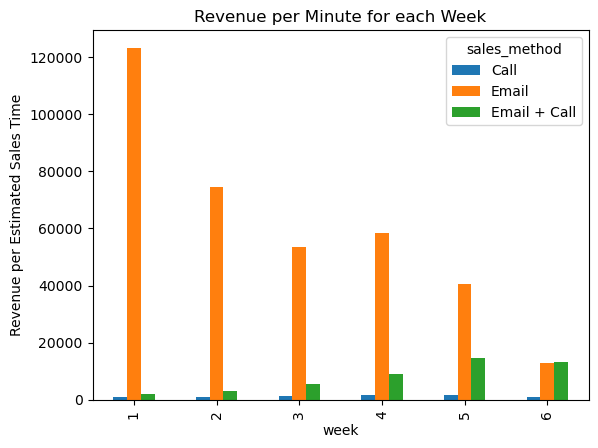

In [34]:
data.groupby(['week','sales_method'])['revenue per estimated sales minutes'].sum().unstack('sales_method').plot(kind='bar')
plt.title('Revenue per Minute for each Week')
plt.ylabel('Revenue per Estimated Sales Time')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_8164\639139686.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(['week','sales_method'])['revenue per estimated sales minutes'].mean().unstack('sales_method').plot(kind='bar')


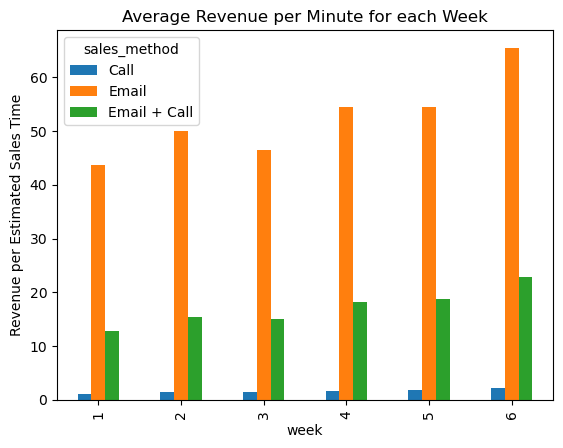

In [35]:
data.groupby(['week','sales_method'])['revenue per estimated sales minutes'].mean().unstack('sales_method').plot(kind='bar')
plt.title('Average Revenue per Minute for each Week')
plt.ylabel('Revenue per Estimated Sales Time')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_8164\2390394686.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('sales_method')['revenue per estimated sales minutes'].sum().plot(kind='bar')


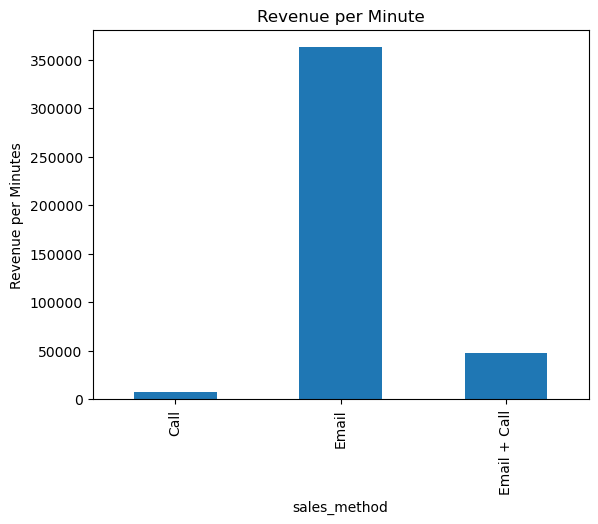

In [36]:
data.groupby('sales_method')['revenue per estimated sales minutes'].sum().plot(kind='bar')
plt.title('Revenue per Minute')
plt.ylabel('Revenue per Minutes')
plt.show()

In [37]:
data.columns

Index(['week', 'sales_method', 'customer_id', 'nb_sold', 'revenue',
       'years_as_customer', 'nb_site_visits', 'state', 'estimated sale time',
       'revenue per estimated sales minutes'],
      dtype='object')

###  Other differences between the customers in each group
- Counting the customers with respect to the sales method, you see the only positive with the Call method. The Call method is responsible for 33% of the total customers, second to Email's 49.7% whilst the Email+Call is responsible for only 17% of the  total customer  base.
- The "Site visits vs revenue and sales method" scatter plot shows that customers that are brought in through Calls tend to yield less revenues than the Email  and Email+Call method. This further strengthen the point of focusing more on Email's and the Email+Call method
- About half of the people who visit the website actually become customers regardless of the sale method, as can be seen by the "nb_sites_visits vs nb_sold" chart.


C:\Users\user\AppData\Local\Temp\ipykernel_8164\2461538570.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('sales_method')[['nb_site_visits','nb_sold']].sum().plot(kind='bar')


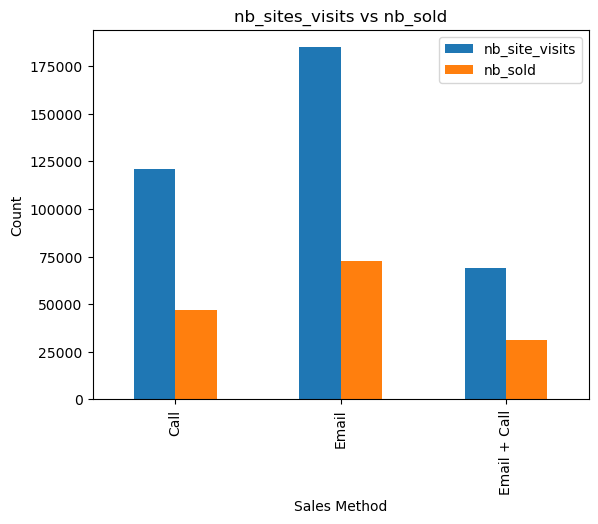

In [64]:
data.groupby('sales_method')[['nb_site_visits','nb_sold']].sum().plot(kind='bar')
plt.xlabel('Sales Method')
plt.ylabel('Count')
plt.title("nb_sites_visits vs nb_sold")
plt.show()

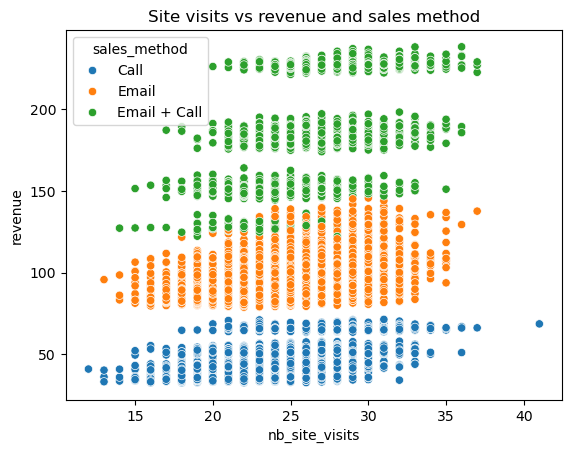

In [65]:
sns.scatterplot(data=data, x='nb_site_visits', y='revenue', hue='sales_method')
plt.title('Site visits vs revenue and sales method')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_8164\2843381793.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('sales_method')['nb_sold'].sum().plot(kind='bar')


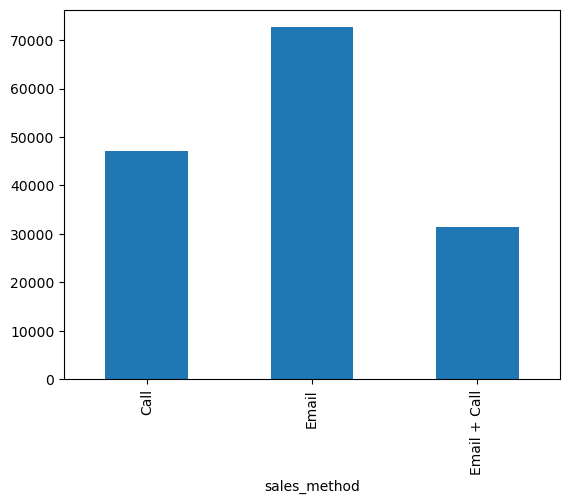

In [66]:
data.groupby('sales_method')['nb_sold'].sum().plot(kind='bar')
plt.show()

In [67]:
total_customers = data['customer_id'].count()

cust_df =  pd.DataFrame({'percentage of customers':(data.groupby('sales_method')['customer_id'].count()/total_customers)*100})
cust_df

C:\Users\user\AppData\Local\Temp\ipykernel_8164\3557378957.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cust_df =  pd.DataFrame({'percentage of customers':(data.groupby('sales_method')['customer_id'].count()/total_customers)*100})


,percentage of customers
sales_method,
Call,33.080000
Email,49.773333
Email + Call,17.146667


C:\Users\user\AppData\Local\Temp\ipykernel_8164\3604863335.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('sales_method')['customer_id'].count().plot(kind='bar')


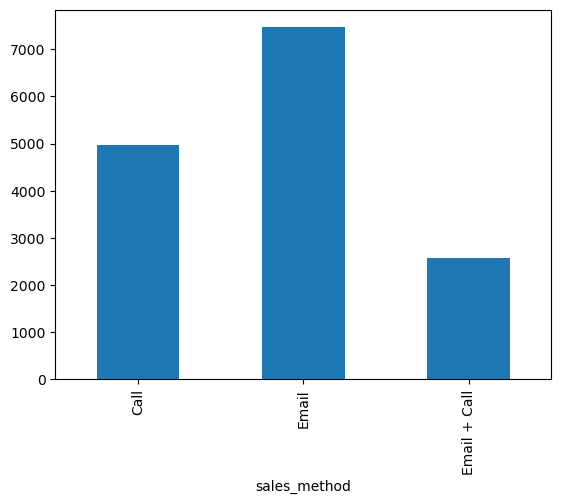

In [68]:
data.groupby('sales_method')['customer_id'].count().plot(kind='bar')
plt.show()

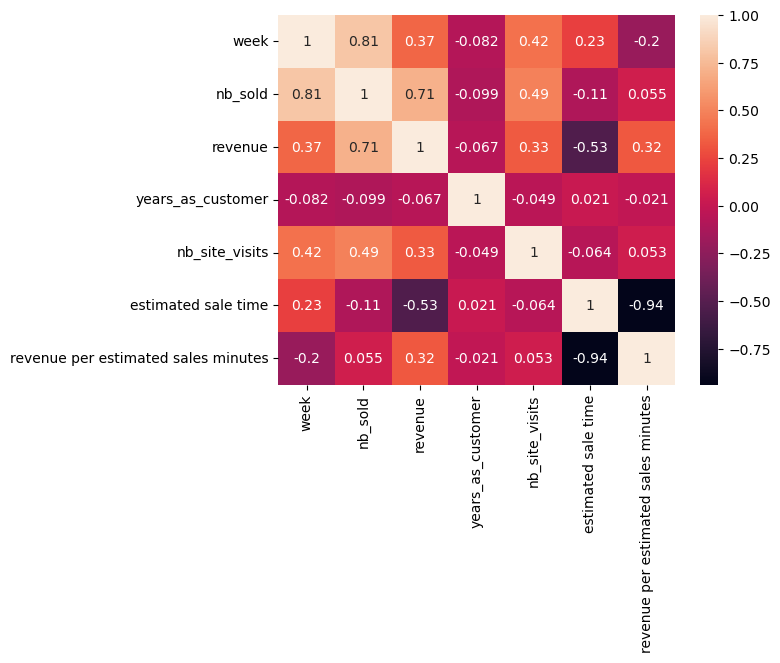

In [69]:
sns.heatmap(data.corr(numeric_only=True), annot=True)
plt.show()

In [70]:
#top_five_states = 
top_5_states_by_revenue = data.groupby(['state'])['revenue'].sum().sort_values(ascending=False).head()
top_5_states_by_revenue

state
California    177062.562583
Texas         114574.541460
New York       90813.636721
Florida        87133.327022
Illinois       57656.776893
Name: revenue, dtype: float64

In [71]:
bottom_5_states_by_revenue = data.groupby('state')['revenue'].sum().sort_values(ascending=True).head()
bottom_5_states_by_revenue

state
Vermont         2974.783210
North Dakota    3153.333068
Wyoming         3180.529054
Delaware        3594.298160
Montana         3777.113401
Name: revenue, dtype: float64

In [72]:
top_5_states_by_customers = data.groupby('state')['revenue'].count().sort_values(ascending=False).head()


C:\Users\user\AppData\Local\Temp\ipykernel_8164\1013125358.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rev_by_method = data.groupby('sales_method')['revenue'].sum()


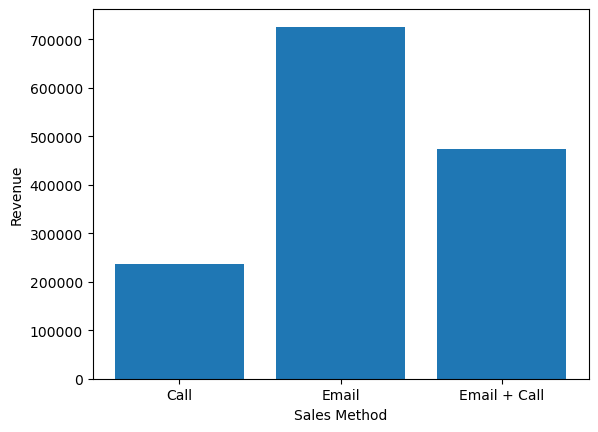

In [73]:
rev_by_method = data.groupby('sales_method')['revenue'].sum()
plt.bar(rev_by_method.index, rev_by_method.values)
plt.xlabel('Sales Method')
plt.ylabel('Revenue')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_8164\2112907833.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_rev_by_method = data.groupby('sales_method')['revenue'].mean()


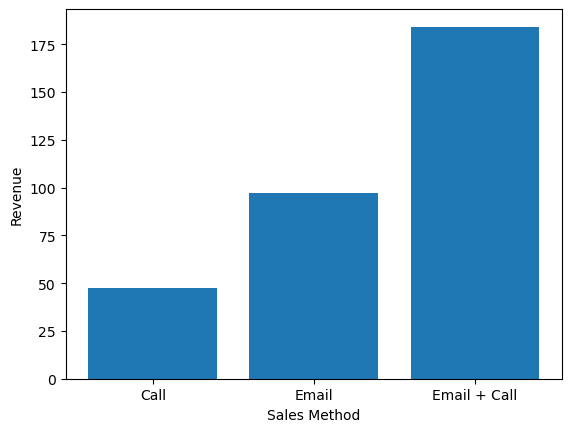

In [74]:
avg_rev_by_method = data.groupby('sales_method')['revenue'].mean()
plt.bar(avg_rev_by_method.index, avg_rev_by_method.values)
plt.xlabel('Sales Method')
plt.ylabel('Revenue')
plt.show()